# Classification: House Style Typology

The `House Style` variable in the Ames dataset describes a property's architectural form. Eight distinct style codes are grouped into four broader classes — Single-story, Multi-story, 1.5-story and Split-level — and a set of classifiers is trained to predict which class a house belongs to using only its geometric and structural measurements. Temporal predictors are deliberately excluded to avoid leakage.

> Run `preprocessing.ipynb` first to generate `preprocessed_data.pkl`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from scipy.stats import uniform

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report)
from sklearn.model_selection import cross_val_score, GridSearchCV, RandomizedSearchCV

In [2]:
from sklearn.preprocessing import LabelEncoder

with open('preprocessed_data.pkl', 'rb') as f:
    data = pickle.load(f)

X_clf            = data['X_clf']
X_train_clf      = data['X_train_clf']
X_test_clf       = data['X_test_clf']
preprocessor_clf = data['preprocessor_clf']

# Encode string class labels to integers.
# XGBoost 3.x stores integer class indices internally; working with strings
# causes a label-mismatch error when the same instance is re-fitted.
# The original names are preserved in class_labels for use in plots / reports.
_le         = LabelEncoder().fit(data['y_clf'])
class_labels = list(_le.classes_)
y_clf        = pd.Series(_le.transform(data['y_clf']),       index=data['y_clf'].index)
y_train_clf  = pd.Series(_le.transform(data['y_train_clf']), index=data['y_train_clf'].index)
y_test_clf   = pd.Series(_le.transform(data['y_test_clf']),  index=data['y_test_clf'].index)

print('Class mapping:')
for i, label in enumerate(class_labels):
    print(f'  {i} → {label}  (n={int((y_clf == i).sum())})')
print(f'\nX_train_clf : {X_train_clf.shape}  |  X_test_clf : {X_test_clf.shape}')

Class mapping:
  0 → 1.5-story  (n=333)
  1 → Multi-story  (n=905)
  2 → Single-story  (n=1481)
  3 → Split-level  (n=211)

X_train_clf : (2344, 30)  |  X_test_clf : (586, 30)


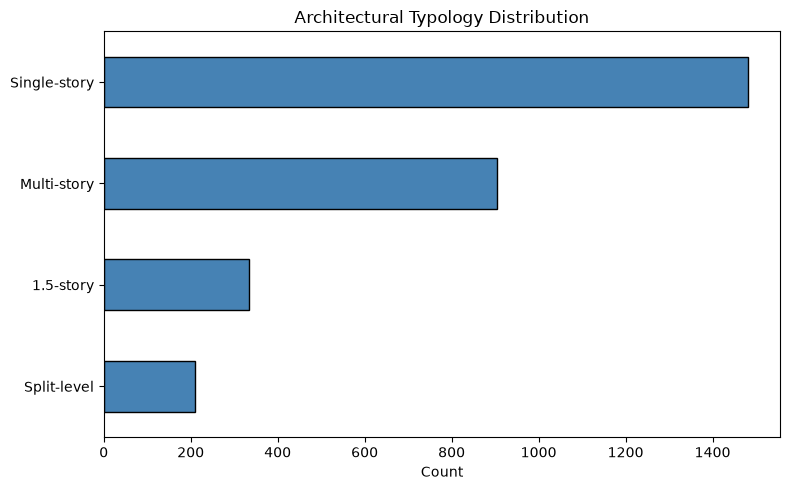

In [3]:
counts = y_clf.value_counts().sort_values()
counts.index = [class_labels[i] for i in counts.index]
plt.figure(figsize=(8, 5))
counts.plot(kind='barh', color='steelblue', edgecolor='black')
plt.title('Architectural Typology Distribution')
plt.xlabel('Count')
plt.tight_layout()
plt.show()

## Classifier Selection

Eight classifiers are compared under the same pipeline structure used for regression: a linear baseline (Logistic Regression), simple non-parametric methods (Decision Tree, KNN), ensemble approaches (Random Forest, Gradient Boosting, XGBoost), a margin-based method (SVC) and a small neural network (MLP). This gives a clear picture of which learning strategy handles the four-class typology problem best.

In [17]:
models = {
    'Logistic Regression':       LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree':             DecisionTreeClassifier(random_state=42),
    'Random Forest':             RandomForestClassifier(random_state=42),
    'Gradient Boosting':         GradientBoostingClassifier(random_state=42),
    'XGBoost':                   XGBClassifier(random_state=42,
                                               eval_metric='mlogloss', verbosity=0),
    'Support Vector Classifier': SVC(random_state=42),
    'K-Nearest Neighbors':       KNeighborsClassifier(n_neighbors=5),
    'Neural Network':            MLPClassifier(random_state=42, max_iter=2000),
}

In [5]:
def evaluation_matrix(model_name, y_true, y_pred):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec  = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1   = f1_score(y_true, y_pred, average='macro', zero_division=0)
    return {
        'Model':             model_name,
        'Accuracy':          round(acc,  4),
        'Precision (macro)': round(prec, 4),
        'Recall (macro)':    round(rec,  4),
        'F1 (macro)':        round(f1,   4),
    }

## Training and Initial Evaluation

In [18]:
trained_models = {}
eval_matrix    = []

for model_name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor_clf),
        ('model', clone(model)),
    ])
    pipeline.fit(X_train_clf, y_train_clf)
    y_pred = pipeline.predict(X_test_clf)
    trained_models[model_name] = y_pred
    eval_matrix.append(evaluation_matrix(model_name, y_test_clf, y_pred))

print('Training complete.')

Training complete.


In [7]:
eval_matrix_df = pd.DataFrame(eval_matrix)
eval_matrix_df

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Logistic Regression,0.8788,0.7920,0.6990,0.7256
1,Decision Tree,0.8498,0.7356,0.7540,0.7439
2,Random Forest,0.8993,0.8967,0.7280,0.7634
3,Gradient Boosting,0.9130,0.8966,0.7788,0.8136
4,XGBoost,0.9147,0.8810,0.8021,0.8333
5,Support Vector Classifier,0.8788,0.9139,0.6695,0.6909
6,K-Nearest Neighbors,0.8430,0.7795,0.6753,0.7104
7,Neural Network,0.8805,0.8037,0.7674,0.7826


In [8]:
best_acc_idx = eval_matrix_df['Accuracy'].idxmax()
best_f1_idx  = eval_matrix_df['F1 (macro)'].idxmax()

best_row = {
    'Model':             'Best Model',
    'Accuracy':          eval_matrix_df.loc[best_acc_idx, 'Model'],
    'Precision (macro)': eval_matrix_df.loc[best_f1_idx,  'Model'],
    'Recall (macro)':    eval_matrix_df.loc[best_f1_idx,  'Model'],
    'F1 (macro)':        eval_matrix_df.loc[best_f1_idx,  'Model'],
}
pd.concat([eval_matrix_df, pd.DataFrame([best_row])], ignore_index=True)

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Logistic Regression,0.8788,0.792,0.699,0.7256
1,Decision Tree,0.8498,0.7356,0.754,0.7439
2,Random Forest,0.8993,0.8967,0.728,0.7634
3,Gradient Boosting,0.913,0.8966,0.7788,0.8136
4,XGBoost,0.9147,0.881,0.8021,0.8333
5,Support Vector Classifier,0.8788,0.9139,0.6695,0.6909
6,K-Nearest Neighbors,0.843,0.7795,0.6753,0.7104
7,Neural Network,0.8805,0.8037,0.7674,0.7826
8,Best Model,XGBoost,XGBoost,XGBoost,XGBoost


## Cross-Validation

Five-fold stratified cross-validation is used to get a more reliable accuracy estimate. Stratification ensures each fold maintains the same class proportions as the full dataset.

In [19]:
cv_results = []
for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor_clf), ('model', clone(model))])
    scores = cross_val_score(pipe, X_clf, y_clf, cv=5, scoring='accuracy')
    cv_results.append({
        'Model':       name,
        'CV Acc mean': f'{scores.mean():.4f}',
        'CV Acc std':  f'+/- {scores.std():.4f}',
    })

cv_results_df = pd.DataFrame(cv_results)
cv_results_df

,Model,CV Acc mean,CV Acc std
0,Logistic Regression,0.8686,+/- 0.0147
1,Decision Tree,0.8522,+/- 0.0179
2,Random Forest,0.9044,+/- 0.0112
3,Gradient Boosting,0.9048,+/- 0.0056
4,XGBoost,0.9099,+/- 0.0103
5,Support Vector Classifier,0.8737,+/- 0.0106
6,K-Nearest Neighbors,0.8358,+/- 0.0240
7,Neural Network,0.8758,+/- 0.0173


## Confusion Matrices

The matrices below reveal where each model misclassifies houses. Systematic confusion between adjacent categories — Multi-story and 1.5-story in particular — is informative about the separability of the typology classes.

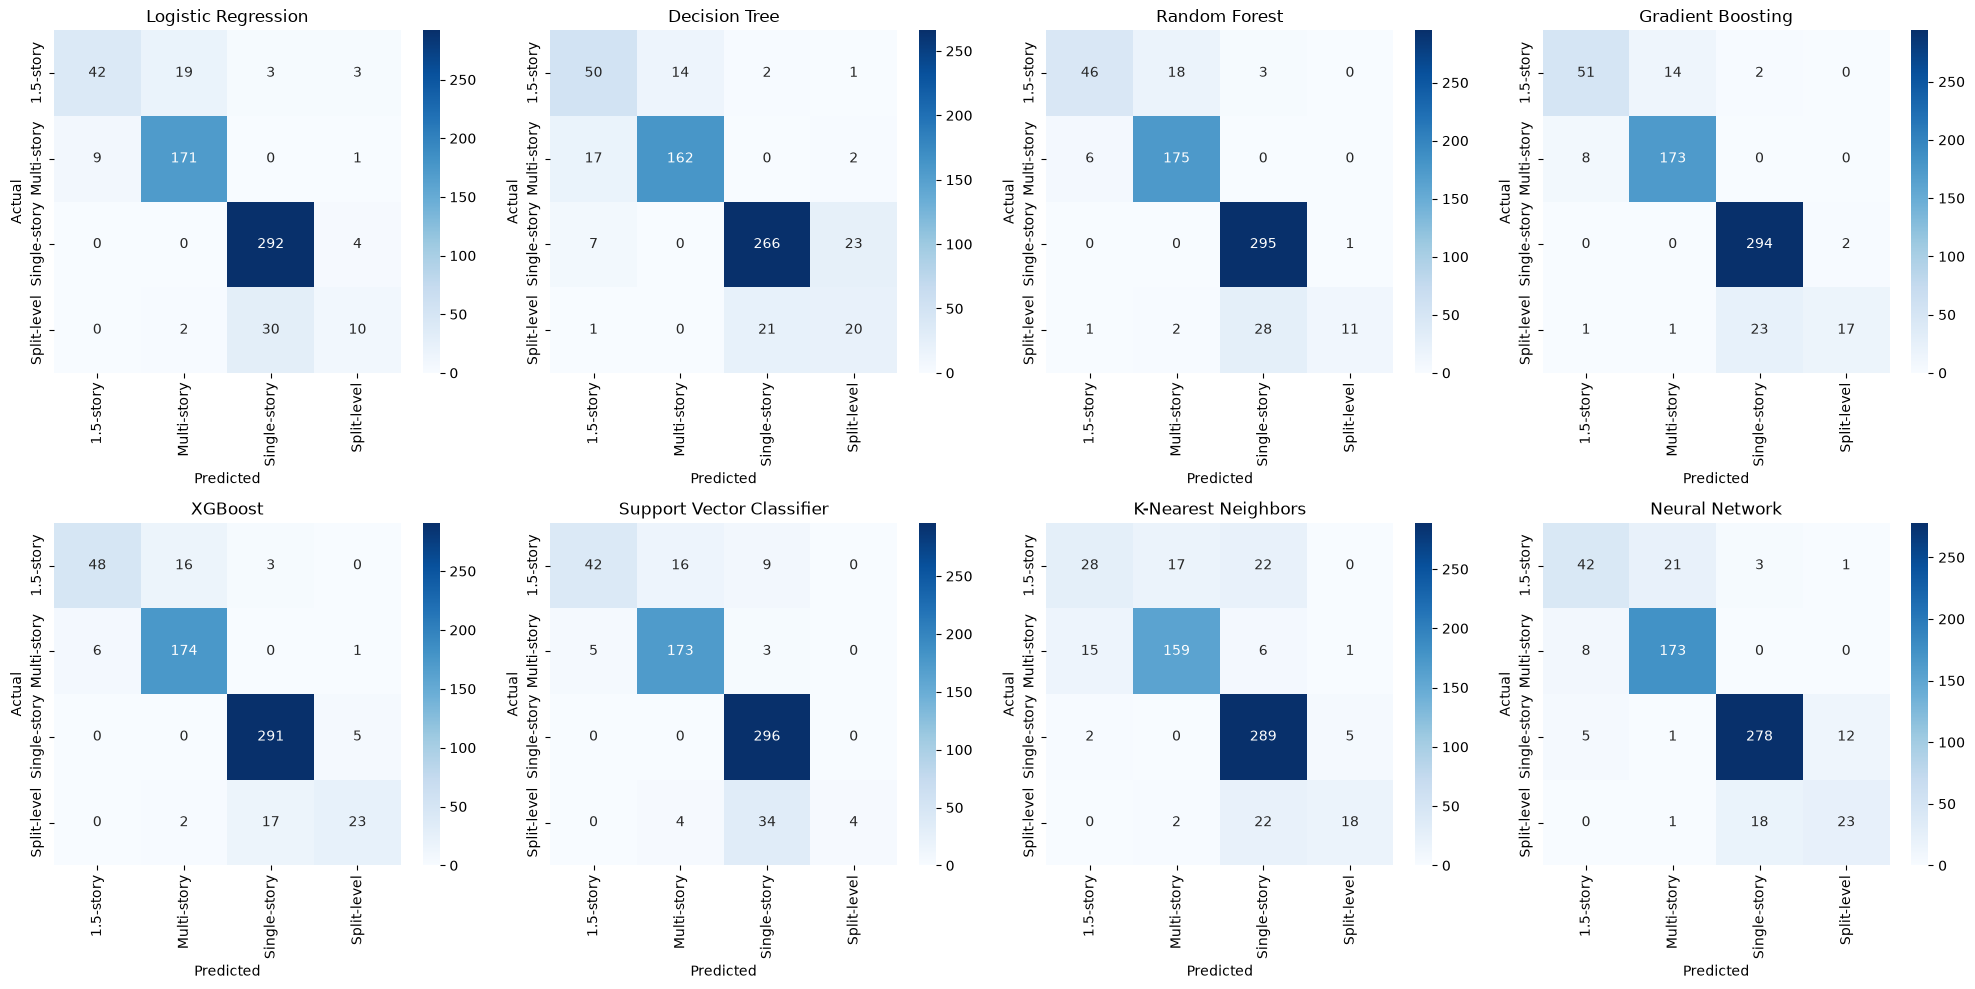

In [10]:
int_labels = sorted(y_clf.unique())   # [0, 1, 2, 3]
n_models   = len(trained_models)
n_cols     = 4
n_rows     = (n_models + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows))
axes = axes.ravel()

for i, (name, y_pred) in enumerate(trained_models.items()):
    cm = confusion_matrix(y_test_clf, y_pred, labels=int_labels)
    sns.heatmap(cm, annot=True, fmt='d', ax=axes[i],
                xticklabels=class_labels, yticklabels=class_labels, cmap='Blues')
    axes[i].set_title(name)
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

## Per-class Performance

In [11]:
for name, y_pred in trained_models.items():
    print(f'=== {name} ===')
    print(classification_report(y_test_clf, y_pred,
                                target_names=class_labels, zero_division=0))

=== Logistic Regression ===
              precision    recall  f1-score   support

   1.5-story       0.82      0.63      0.71        67
 Multi-story       0.89      0.94      0.92       181
Single-story       0.90      0.99      0.94       296
 Split-level       0.56      0.24      0.33        42

    accuracy                           0.88       586
   macro avg       0.79      0.70      0.73       586
weighted avg       0.86      0.88      0.86       586

=== Decision Tree ===
              precision    recall  f1-score   support

   1.5-story       0.67      0.75      0.70        67
 Multi-story       0.92      0.90      0.91       181
Single-story       0.92      0.90      0.91       296
 Split-level       0.43      0.48      0.45        42

    accuracy                           0.85       586
   macro avg       0.74      0.75      0.74       586
weighted avg       0.86      0.85      0.85       586

=== Random Forest ===
              precision    recall  f1-score   support

   

## Hyperparameter Tuning

The four best-performing classifiers are tuned using cross-validated search, with macro F1 as the scoring criterion to weight all four classes equally. Random Forest and XGBoost use a randomised search; Gradient Boosting and SVC use an exhaustive grid search.

In [12]:
param_grids = {
    'Random Forest': {
        'model__n_estimators':      [50, 100, 200],
        'model__max_depth':         [None, 10, 20],
        'model__min_samples_split': [2, 5, 10],
    },
    'Gradient Boosting': {
        'model__n_estimators':  [50, 100, 200],
        'model__learning_rate': [0.01, 0.1, 0.2],
        'model__max_depth':     [3, 5, 7],
    },
    'XGBoost': {
        'model__n_estimators':  [50, 100, 200],
        'model__learning_rate': uniform(0.01, 0.3),
        'model__max_depth':     [3, 5, 7],
    },
    'Support Vector Classifier': {
        'model__kernel': ['linear', 'rbf'],
        'model__C':      [0.1, 1, 10],
        'model__gamma':  ['scale', 'auto'],
    },
}

In [13]:
tune_models = {
    'Random Forest':             RandomForestClassifier(random_state=42),
    'Gradient Boosting':         GradientBoostingClassifier(random_state=42),
    'XGBoost':                   XGBClassifier(random_state=42,
                                               eval_metric='mlogloss', verbosity=0),
    'Support Vector Classifier': SVC(random_state=42),
}
best_models = {}

In [14]:
for name, model in tune_models.items():
    print(f'Tuning {name}...')
    pipe = Pipeline(steps=[('preprocessor', preprocessor_clf), ('model', model)])

    if name in ['Random Forest', 'XGBoost']:
        search = RandomizedSearchCV(
            pipe, param_distributions=param_grids[name],
            n_iter=10, cv=5, scoring='f1_macro',
            n_jobs=-1, random_state=42,
        )
    else:
        search = GridSearchCV(
            pipe, param_grid=param_grids[name],
            cv=5, scoring='f1_macro', n_jobs=-1,
        )

    search.fit(X_train_clf, y_train_clf)
    best_models[name] = search.best_estimator_
    print(f'  Best params      : {search.best_params_}')
    print(f'  Best CV F1 (mac) : {search.best_score_:.4f}')
    print()

Tuning Random Forest...
  Best params      : {'model__n_estimators': 50, 'model__min_samples_split': 5, 'model__max_depth': 20}
  Best CV F1 (mac) : 0.7725

Tuning Gradient Boosting...
  Best params      : {'model__learning_rate': 0.2, 'model__max_depth': 3, 'model__n_estimators': 100}
  Best CV F1 (mac) : 0.8058

Tuning XGBoost...
  Best params      : {'model__learning_rate': np.float64(0.13958350559263474), 'model__max_depth': 3, 'model__n_estimators': 200}
  Best CV F1 (mac) : 0.8082

Tuning Support Vector Classifier...
  Best params      : {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
  Best CV F1 (mac) : 0.7785



## Results after Tuning

In [15]:
eval_matrix = []
for name, model in best_models.items():
    y_pred = model.predict(X_test_clf)
    eval_matrix.append(evaluation_matrix(name, y_test_clf, y_pred))

eval_matrix_df = pd.DataFrame(eval_matrix)
eval_matrix_df

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Random Forest,0.8993,0.8933,0.7349,0.7698
1,Gradient Boosting,0.9096,0.8843,0.7769,0.8113
2,XGBoost,0.9181,0.8839,0.8055,0.8366
3,Support Vector Classifier,0.8959,0.8458,0.7650,0.7959


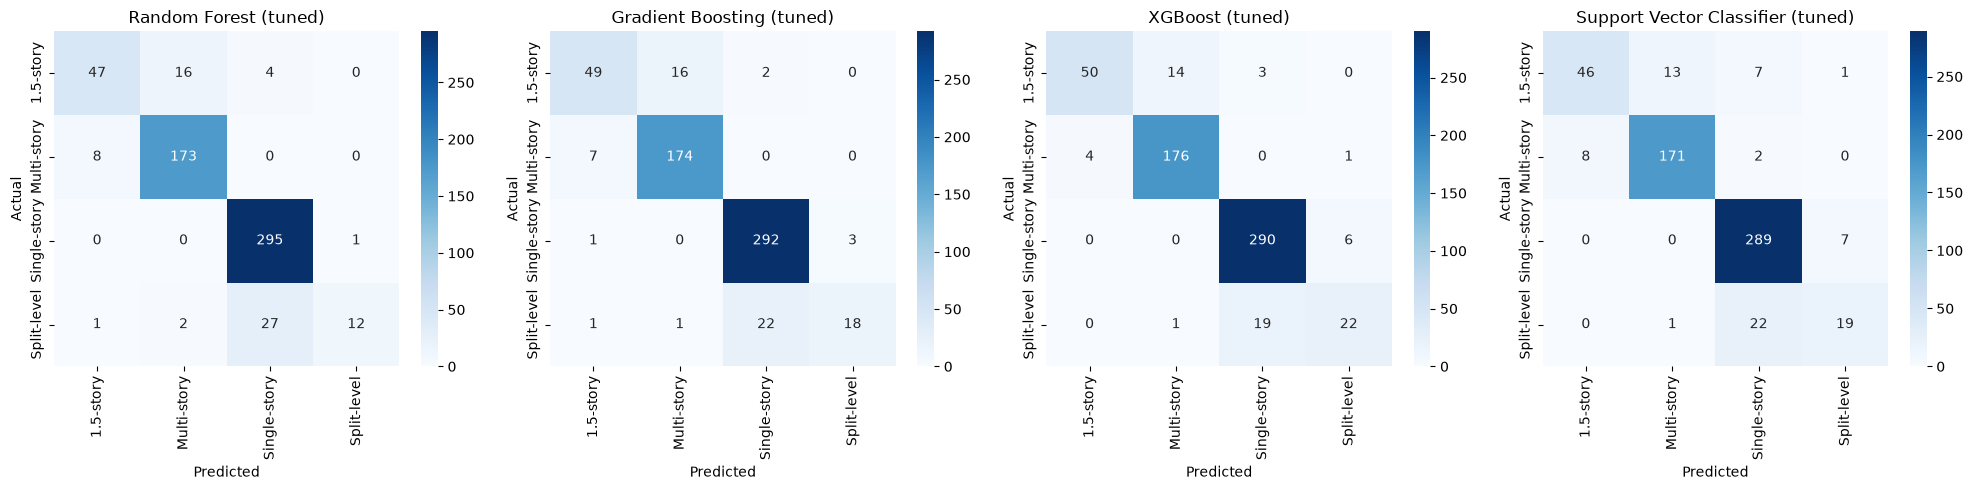

In [16]:
int_labels = sorted(y_clf.unique())
fig, axes  = plt.subplots(1, len(best_models), figsize=(5 * len(best_models), 5))
if len(best_models) == 1:
    axes = [axes]

for i, (name, model) in enumerate(best_models.items()):
    y_pred = model.predict(X_test_clf)
    cm = confusion_matrix(y_test_clf, y_pred, labels=int_labels)
    sns.heatmap(cm, annot=True, fmt='d', ax=axes[i],
                xticklabels=class_labels, yticklabels=class_labels, cmap='Blues')
    axes[i].set_title(f'{name} (tuned)')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.tight_layout()
plt.show()